# 10 · Calibration, final-model rule and the test run (Step 7)

**Order matters here, and the files show it:**

1. `final_fit`: every family is refitted on all training rows available at 2013-09-01 (5 seeds, fixed epochs = mean CV best epoch, rounded up). Scores need no labels.
2. `calibrate`: the Phase 1 **Sep → Oct** rule for every model (fit on September, check ECE on October, adopt a recalibrator only if it beats raw by > 0.005), with the candidate set extended by temperature scaling (Guo et al., 2017) and the causal 28-day rolling Platt and rolling temperature calibrators (Phase 1's rule compared only the static ones, so its deployed LogReg used static Platt); thresholds frozen on Sep–Oct; the **final model chosen by CV**. No test label is read.
3. `final` (only with `--final`, refused while the protocol has uncommitted changes): the one test evaluation.

This notebook only reads the saved results.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
for p in (ROOT / 'src', ROOT.parent / 'phase1' / 'src'):
    sys.path.insert(0, str(p))

import aerocast_dl  # torch before XGBoost (OpenMP)
import numpy as np, pandas as pd
from IPython.display import Image, display
from aerocast_dl import config, pipeline
R, F = config.RESULTS_DIR, config.FIGURES_DIR
pd.set_option('display.precision', 4)


## 1. Calibrator selection on October

In [2]:
cal = pd.read_csv(R / 'calibrator_selection.csv')
sel = json.loads((R / 'selection.json').read_text())
print('chosen:', sel['calibrator'])
cal.pivot(index='calibrator', columns='model', values='check_ece').round(4)

chosen: {'logreg': 'rolling_platt28', 'xgboost': 'raw', 'mlp': 'rolling_platt28', 'gru': 'rolling_platt28', 'wide_deep': 'rolling_platt28', 'emb_xgb': 'rolling_temperature28'}


model,emb_xgb,gru,logreg,mlp,wide_deep,xgboost
calibrator,,,,,,
isotonic,0.0429,0.0300,0.0339,0.0410,0.0355,0.0427
platt,0.0421,0.0295,0.0329,0.0400,0.0346,0.0432
raw,0.0307,0.0643,0.0626,0.0376,0.0584,0.0235
rolling_platt28,0.0319,0.0196,0.0213,0.0255,0.0226,0.0306
rolling_temperature28,0.0251,0.0303,0.0315,0.0287,0.0345,0.0237
temperature,0.0310,0.0314,0.0326,0.0372,0.0362,0.0317


## 2. The final-model rule (cross-validation only)

Highest mean rolling-CV AP as deployed; within 0.005 of the best, the model with fewer trainable parameters.

In [3]:
pd.DataFrame({'cv_pr_auc': sel['cv_pr_auc'], 'parameters': sel['complexity']}).sort_values('cv_pr_auc', ascending=False).assign(within_0_005=lambda d: d.index.isin(sel['within_0.005']))

,cv_pr_auc,parameters,within_0_005
logreg,0.4714,154,True
wide_deep,0.4691,37255,True
gru,0.4672,37101,True
mlp,0.4655,27501,False
emb_xgb,0.4505,28257,False
xgboost,0.4500,756,False


In [4]:
print('final model:', sel['final_model'])

final model: logreg


## 3. Test (Nov–Dec), each model with its rule-selected calibrator

The paired day-block bootstrap compares each model with Phase 1 LogReg on the same days; an interval that contains 0 establishes neither a difference nor equivalence.

In [5]:
m = pd.read_csv(R / 'test_metrics.csv')
head = m[(m.split == 'test') & m.rule_selected].set_index('label')
head[['calibration', 'pr_auc', 'roc_auc', 'brier', 'ece', 'precision_at_thr', 'recall_at_thr']]

,calibration,pr_auc,roc_auc,brier,ece,precision_at_thr,recall_at_thr
label,,,,,,,
Phase 1 LogReg,rolling_platt28,0.3916,0.6570,0.1810,0.0271,0.5470,0.0404
Phase 1 XGBoost,raw,0.4074,0.6655,0.1793,0.0269,0.5489,0.0696
Embedding MLP,rolling_platt28,0.3949,0.6678,0.1797,0.0266,0.5217,0.0052
MLP + GRU history,rolling_platt28,0.3980,0.6678,0.1800,0.0348,NaN,0.0000
Wide & Deep (LogReg + deep),rolling_platt28,0.3989,0.6645,0.1799,0.0281,0.5379,0.0708
MLP embeddings -> XGBoost,rolling_temperature28,0.4005,0.6640,0.1794,0.0174,0.4669,0.2107


In [6]:
boot = json.loads((R / 'test_bootstrap.json').read_text())
pd.DataFrame({k: {'AP diff vs LogReg': v['pr_auc']['diff'], 'CI low': v['pr_auc']['ci_lo'], 'CI high': v['pr_auc']['ci_hi']} for k, v in boot.items()}).T

,AP diff vs LogReg,CI low,CI high
xgboost,0.0158,-0.0121,0.0432
mlp,0.0034,-0.0148,0.0270
gru,0.0064,-0.0130,0.0275
wide_deep,0.0073,-0.0051,0.0228
emb_xgb,0.0089,-0.0143,0.0326


In [7]:
pol = pd.read_csv(R / 'test_policies.csv')
pol[pol.policy == 'daily top 10%'].set_index('label')[['precision', 'recall', 'lift', 'f1', 'accuracy']]

,precision,recall,lift,f1,accuracy
label,,,,,
Phase 1 LogReg,0.4477,0.1742,1.7332,0.2509,0.7312
Phase 1 XGBoost,0.4383,0.1706,1.6968,0.2456,0.7293
Embedding MLP,0.4493,0.1749,1.7396,0.2518,0.7315
MLP + GRU history,0.4504,0.1753,1.7439,0.2524,0.7317
Wide & Deep (LogReg + deep),0.4460,0.1736,1.7267,0.2499,0.7308
MLP embeddings -> XGBoost,0.4422,0.1721,1.7118,0.2478,0.7301


In [8]:
m[m.rule_selected & m.split.isin(['test_m11', 'test_m12'])].pivot(index='label', columns='split', values='ece').round(4)

split,test_m11,test_m12
label,,
Embedding MLP,0.0096,0.0470
MLP + GRU history,0.0085,0.0649
MLP embeddings -> XGBoost,0.0161,0.0323
Phase 1 LogReg,0.0051,0.0503
Phase 1 XGBoost,0.0178,0.0661
Wide & Deep (LogReg + deep),0.0073,0.0524


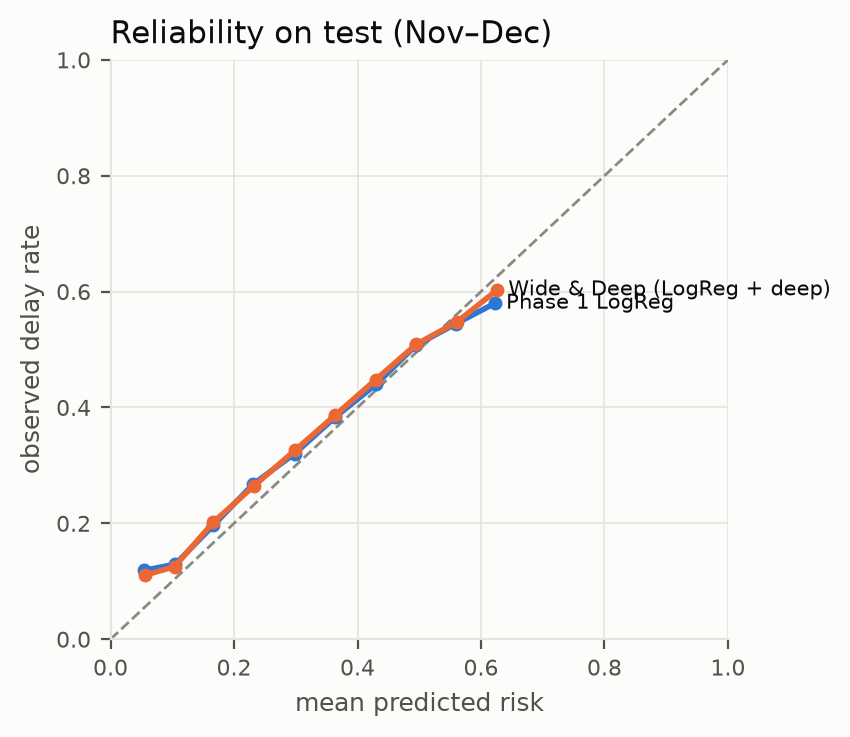

In [9]:
display(Image(F / 'reliability_test.png', width=420))

## 4. Precision–recall and confusion matrices

The curves overlap almost everywhere; the AP ranking in the labels is what differs. The confusion matrices are for the final model (Phase 1 LogReg) at its two operating points.

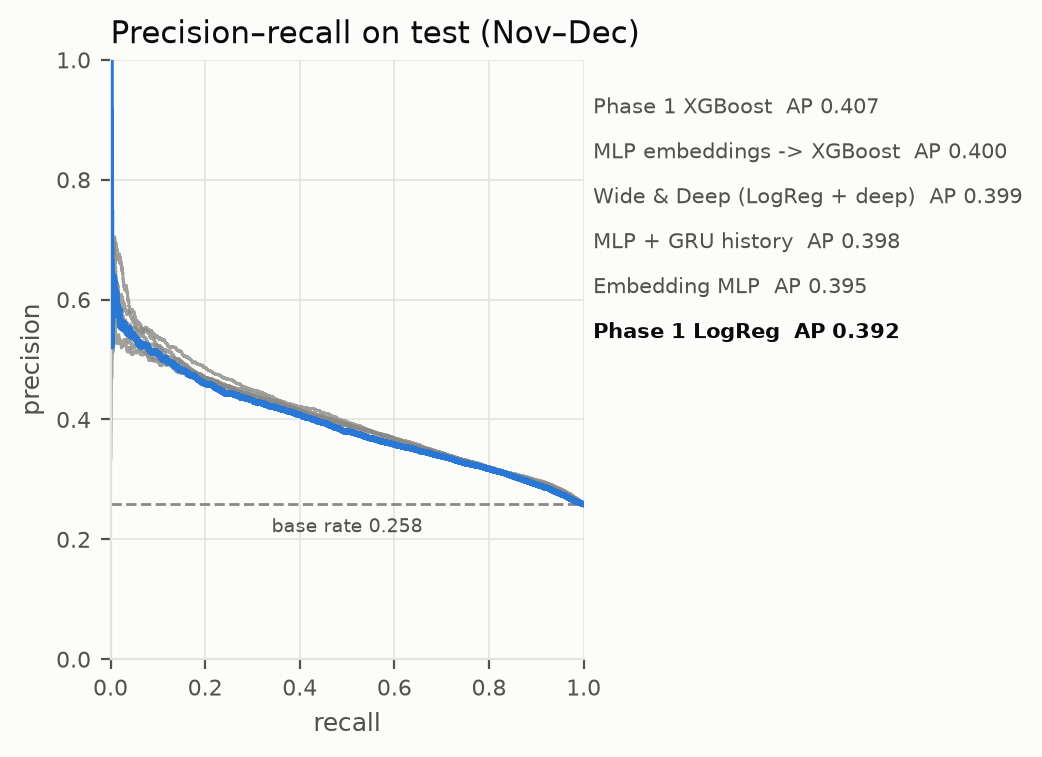

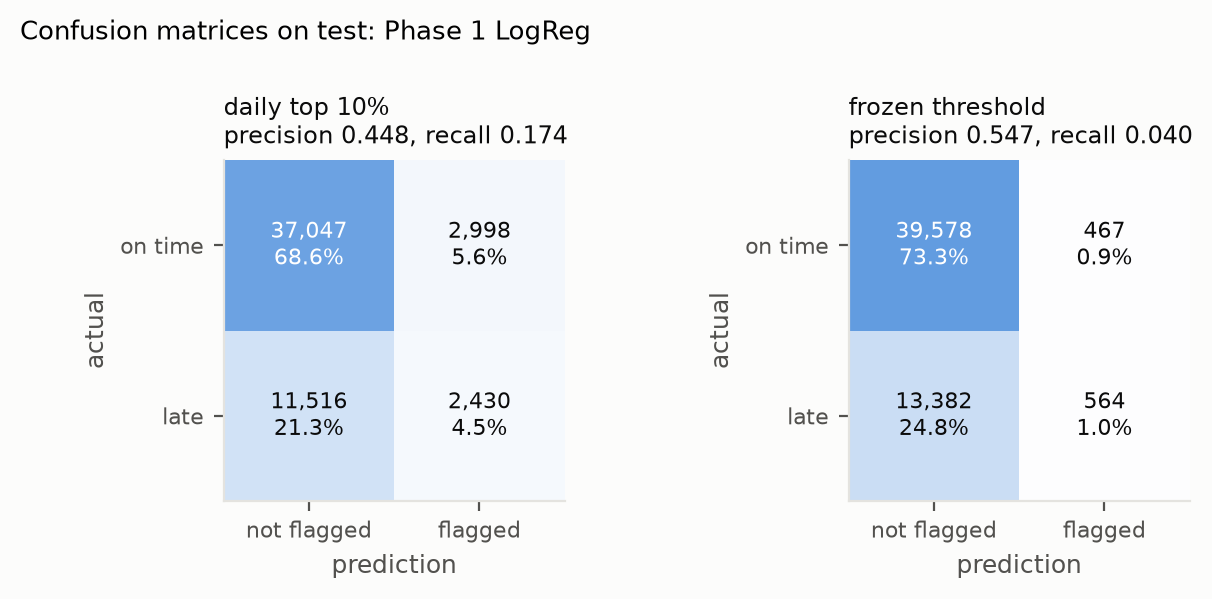

In [10]:
display(Image(F / 'pr_curves_test.png', width=520))
display(Image(F / 'confusion_test.png', width=620))

In [11]:
pol[pol.policy.str.startswith('frozen')].set_index('label')[['threshold', 'flag_rate', 'precision', 'recall', 'f1', 'tp', 'fp', 'fn', 'tn']]

,threshold,flag_rate,precision,recall,f1,tp,fp,fn,tn
label,,,,,,,,,
Phase 1 LogReg,0.5079,0.0191,0.5470,0.0404,0.0753,564,467,13382,39578
Phase 1 XGBoost,0.4838,0.0328,0.5489,0.0696,0.1236,971,798,12975,39247
Embedding MLP,0.6263,0.0026,0.5217,0.0052,0.0102,72,66,13874,39979
MLP + GRU history,0.6881,0.0000,NaN,0.0000,0.0000,0,0,13946,40045
Wide & Deep (LogReg + deep),0.4765,0.0340,0.5379,0.0708,0.1251,987,848,12959,39197
MLP embeddings -> XGBoost,0.4056,0.1166,0.4669,0.2107,0.2904,2939,3356,11007,36689


## 5. Where the deep models differ from LogReg (slices)

AP gain over LogReg per slice. Frequencies are training-row counts on the final training rows; destinations with fewer than 50 rows share the embedding UNK row. `stable = False` marks slices with fewer than 30 late flights. These are descriptive: no interval is attached, and nothing was chosen from them.

In [12]:
sl = pd.read_csv(R / 'test_slices.csv')
cols = ['n', 'late', 'stable', 'ap_logreg', 'ap_gain_mlp', 'ap_gain_gru', 'ap_gain_wide_deep', 'ap_gain_xgboost', 'ap_gain_emb_xgb']
for dim in ['dest_train_rows', 'route_train_rows', 'dep_hour']:
    display(sl[sl.dimension == dim].set_index('slice')[cols].round(4))

,n,late,stable,ap_logreg,ap_gain_mlp,ap_gain_gru,ap_gain_wide_deep,ap_gain_xgboost,ap_gain_emb_xgb
slice,,,,,,,,,
50-499,2342,719,True,0.4240,-0.0047,-0.0080,0.0025,0.0160,0.0035
"500-1,999",8367,2334,True,0.4225,0.0005,-0.0021,0.0020,0.0113,0.0085
< 50,93,35,True,0.3844,0.0543,0.0589,0.0172,0.0412,0.0392
">= 2,000",43189,10858,True,0.3826,0.0048,0.0093,0.0088,0.0166,0.0094


,n,late,stable,ap_logreg,ap_gain_mlp,ap_gain_gru,ap_gain_wide_deep,ap_gain_xgboost,ap_gain_emb_xgb
slice,,,,,,,,,
50-499,5136,1431,True,0.4114,-0.0079,-0.0106,0.0033,0.0112,0.0044
"500-1,999",21349,5732,True,0.4113,0.0047,0.0059,0.0062,0.0158,0.0117
< 50,648,197,True,0.3535,0.0121,0.0093,0.0068,0.0227,0.0106
">= 2,000",26858,6586,True,0.3724,0.0030,0.0089,0.0091,0.0151,0.0060


,n,late,stable,ap_logreg,ap_gain_mlp,ap_gain_gru,ap_gain_wide_deep,ap_gain_xgboost,ap_gain_emb_xgb
slice,,,,,,,,,
05-09,15805,2812,True,0.2681,0.0072,0.0168,0.0100,0.0033,-0.0024
10-13,11536,2640,True,0.3193,0.0051,0.0151,0.0097,0.0042,-0.0053
14-17,14691,4355,True,0.4149,0.0022,0.0042,0.0061,0.0103,0.0066
18-23,11959,4139,True,0.4543,0.0017,0.0006,0.0074,0.0327,0.0219


In [13]:
sl[sl.dimension == 'carrier'].set_index('slice')[cols].sort_values('n', ascending=False).round(4)

,n,late,stable,ap_logreg,ap_gain_mlp,ap_gain_gru,ap_gain_wide_deep,ap_gain_xgboost,ap_gain_emb_xgb
slice,,,,,,,,,
UA,9646,2480,True,0.3594,0.0068,0.0093,0.0150,-0.0001,-0.0022
B6,8929,2580,True,0.4545,0.0000,0.0047,0.0062,0.0120,0.0147
EV,8272,2595,True,0.4598,0.0057,0.0005,0.0032,0.0106,0.0065
DL,7905,1460,True,0.2440,0.0093,0.0109,0.0053,0.0323,0.0191
AA,5147,1090,True,0.2636,0.0195,0.0250,0.0132,0.0348,0.0207
MQ,3992,1155,True,0.3703,0.0076,0.0094,0.0101,0.0389,0.0263
US,3206,590,True,0.2603,0.0044,0.0101,0.0084,0.0314,0.0176
9E,3106,786,True,0.3218,0.0129,0.0092,0.0063,0.0375,0.0292
WN,2100,715,True,0.5600,-0.0031,0.0003,0.0093,0.0147,0.0116


## 6. Drift (PSI, training rows as reference)

< 0.1 stable, 0.1–0.25 moderate, > 0.25 large. Tree-model scores shift most between train and Sep–Oct because their training-row scores are in-sample; every network and LogReg score is stable on Nov–Dec.

In [14]:
pd.read_csv(R / 'test_drift.csv').set_index('input').round(3)

,calib,test
input,,
category: carrier,0.004,0.002
category: origin,0.004,0.002
score: emb_xgb,0.333,0.061
score: gru,0.082,0.003
score: logreg,0.079,0.011
score: mlp,0.170,0.017
score: wide_deep,0.077,0.011
score: xgboost,0.378,0.076
